# Kumasi Traffic Congestion Classifier
Predicting the **congestion level** (Low / Moderate / Heavy / Severe) on major Kumasi corridors such as Kejetia-Adum, Santasi Roundabout, Suame Magazine and KNUST Gate, using a Random Forest classifier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

**Read the data**

In [2]:
df = pd.read_csv('Kumasi_Traffic.csv')

**Display some rows**

In [3]:
df.head()

,congestion_level,corridor,day_of_week,hour,lanes,vehicle_count,trotro_share,rainfall_mm,marketday,schoolzone,roadworks,trafficlight_working,accident_reported,event_nearby
0,Low,Asokwa Interchange,Friday,13,2,90,29,0.0,no,no,no,yes,no,no
1,Moderate,Tafo-Pankrono,Friday,17,3,114,26,0.0,no,no,no,yes,no,no
2,Moderate,Suame Magazine,Monday,12,2,121,28,0.0,no,no,no,yes,no,no
3,Low,Ahodwo Roundabout,Thursday,12,4,98,26,0.0,no,no,no,yes,no,no
4,Moderate,Ahodwo Roundabout,Tuesday,17,3,121,43,0.0,no,no,no,yes,no,no


**View the number of rows and columns in the data**

In [4]:
df.shape

(600, 14)

**View summary statistics**

In [5]:
df.describe()

,hour,lanes,vehicle_count,trotro_share,rainfall_mm
count,600.000000,600.000000,600.000000,600.000000,600.000000
mean,13.041667,2.345000,111.081667,34.711667,0.429167
std,4.665427,0.844885,24.318044,8.849806,2.125621
min,5.000000,1.000000,38.000000,8.000000,0.000000
25%,8.000000,2.000000,94.000000,28.000000,0.000000
50%,13.000000,2.000000,111.000000,35.000000,0.000000
75%,17.000000,3.000000,129.000000,41.000000,0.000000
max,22.000000,4.000000,177.000000,63.000000,22.100000


**View data types and non-null counts**

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   congestion_level      600 non-null    str    
 1   corridor              600 non-null    str    
 2   day_of_week           600 non-null    str    
 3   hour                  600 non-null    int64  
 4   lanes                 600 non-null    int64  
 5   vehicle_count         600 non-null    int64  
 6   trotro_share          600 non-null    int64  
 7   rainfall_mm           600 non-null    float64
 8   marketday             600 non-null    str    
 9   schoolzone            600 non-null    str    
 10  roadworks             600 non-null    str    
 11  trafficlight_working  600 non-null    str    
 12  accident_reported     600 non-null    str    
 13  event_nearby          600 non-null    str    
dtypes: float64(1), int64(4), str(9)
memory usage: 65.8 KB


**Look if there are any duplicate rows in the dataset**

In [7]:
df.loc[df.duplicated()]

,congestion_level,corridor,day_of_week,hour,lanes,vehicle_count,trotro_share,rainfall_mm,marketday,schoolzone,roadworks,trafficlight_working,accident_reported,event_nearby


No duplicate rows

**Get the name of the columns**

In [8]:
df.columns

Index(['congestion_level', 'corridor', 'day_of_week', 'hour', 'lanes',
       'vehicle_count', 'trotro_share', 'rainfall_mm', 'marketday',
       'schoolzone', 'roadworks', 'trafficlight_working', 'accident_reported',
       'event_nearby'],
      dtype='str')

**Check for null values**

In [9]:
df.isna().sum()

congestion_level        0
corridor                0
day_of_week             0
hour                    0
lanes                   0
vehicle_count           0
trotro_share            0
rainfall_mm             0
marketday               0
schoolzone              0
roadworks               0
trafficlight_working    0
accident_reported       0
event_nearby            0
dtype: int64

No missing values

**Let's do a bit of EDA!**

**Target variable: congestion level**

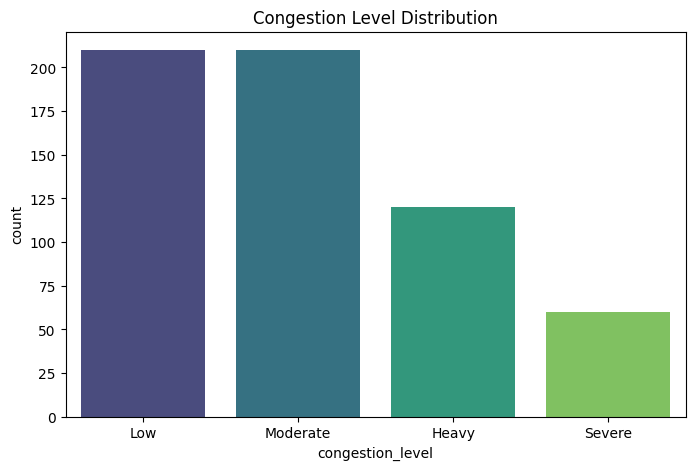

congestion_level
Low         0.35
Moderate    0.35
Heavy       0.20
Severe      0.10
Name: proportion, dtype: float64


In [10]:
order = ['Low','Moderate','Heavy','Severe']
plt.figure(figsize=(8,5))
sns.countplot(x='congestion_level', data=df, order=order, palette='viridis')
plt.title('Congestion Level Distribution')
plt.show()
print(df.congestion_level.value_counts(normalize=True).round(3))

Inference: Low and Moderate dominate; Severe is the rarest class, so the model must be checked per class and not on accuracy alone.

**Congestion by corridor**

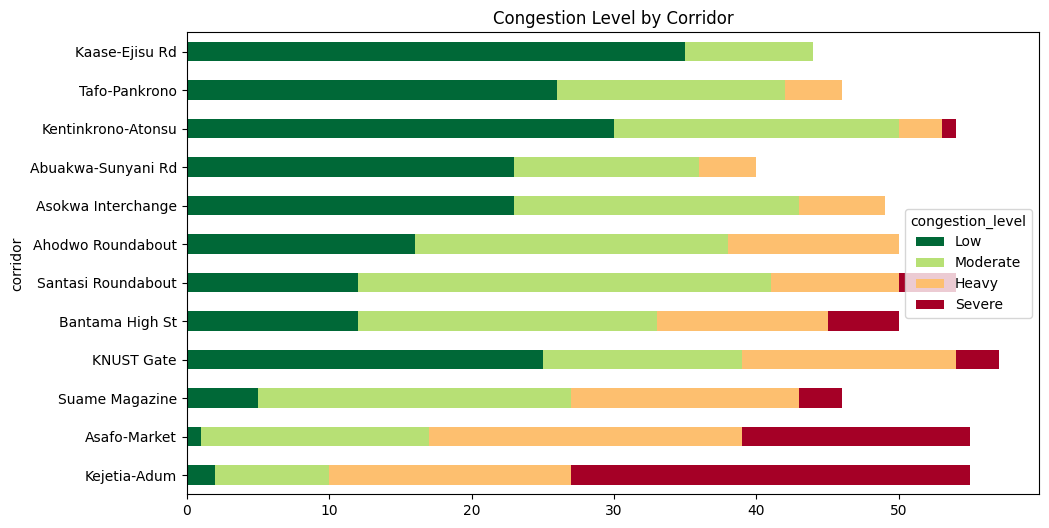

In [11]:
ct = pd.crosstab(df.corridor, df.congestion_level)[order]
ct = ct.loc[ct['Heavy'].add(ct['Severe']).sort_values(ascending=False).index]
ct.plot(kind='barh', stacked=True, figsize=(11,6), colormap='RdYlGn_r')
plt.title('Congestion Level by Corridor')
plt.show()

Inference: the central market corridors (Kejetia-Adum, Asafo-Market) and the roundabouts carry most of the Heavy/Severe cases, while Abuakwa and Kaase roads are mostly Low.

**Visualising categorical data**

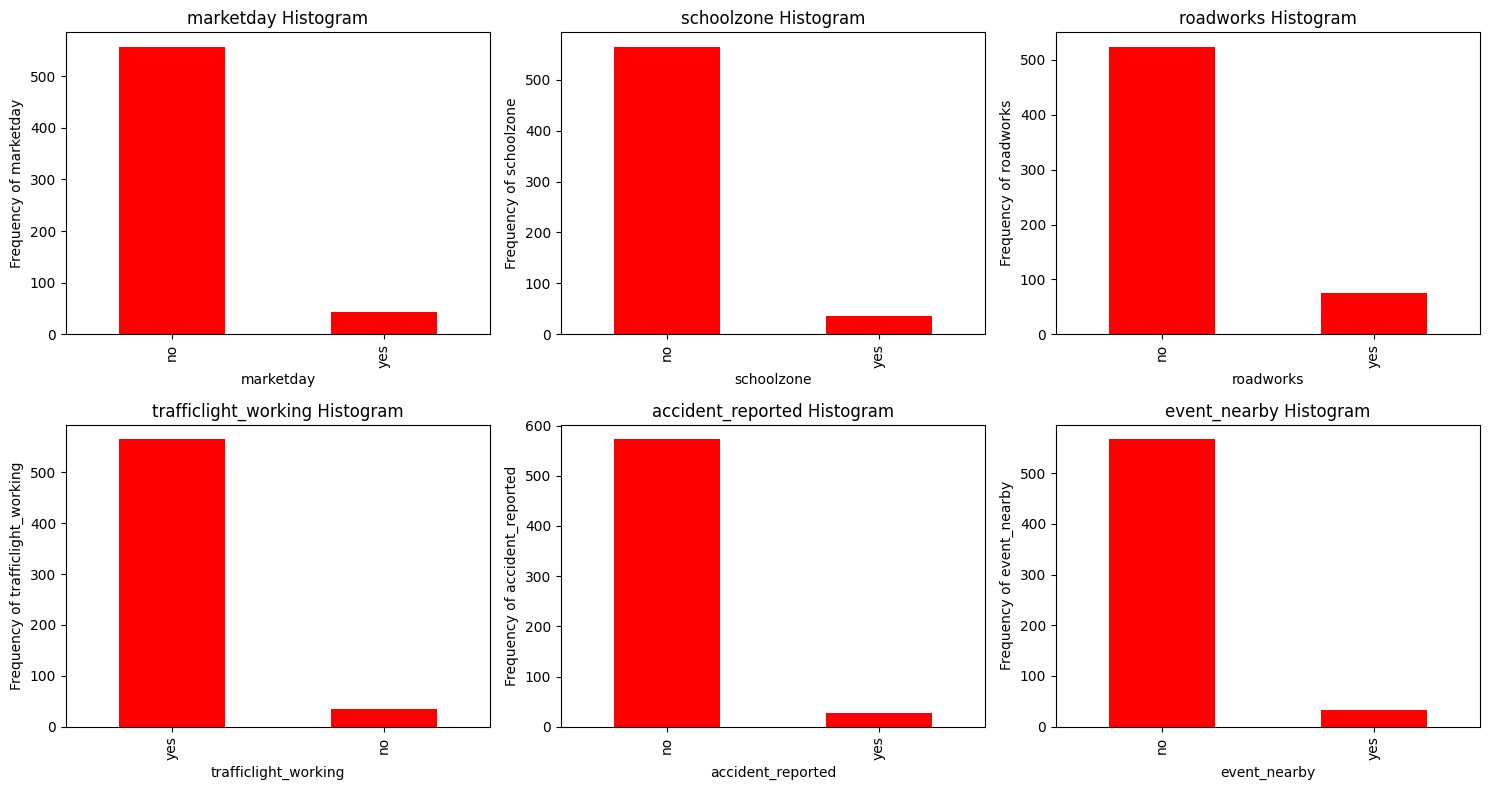

In [12]:
binary_cols = ['marketday','schoolzone','roadworks','trafficlight_working','accident_reported','event_nearby']
plt.figure(figsize=(15,8))
for i,col in enumerate(binary_cols,1):
    plt.subplot(2,3,i)
    df[col].value_counts().plot(kind='bar', color='r')
    plt.title(col+' Histogram'); plt.xlabel(col); plt.ylabel('Frequency of '+col)
plt.tight_layout(); plt.show()

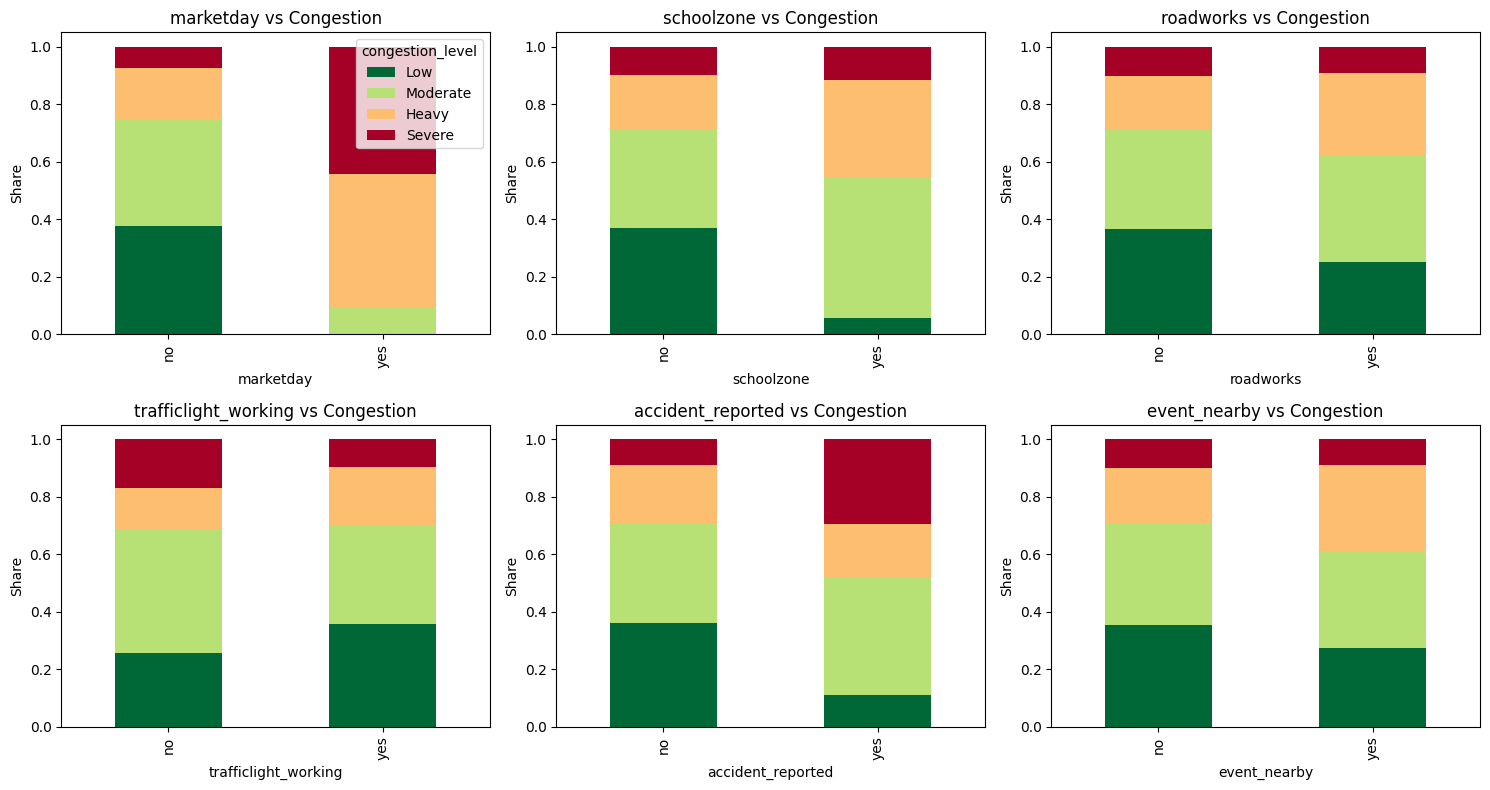

In [13]:
plt.figure(figsize=(15,8))
for i,col in enumerate(binary_cols,1):
    plt.subplot(2,3,i)
    pd.crosstab(df[col], df.congestion_level, normalize='index')[order].plot(kind='bar', stacked=True, ax=plt.gca(), colormap='RdYlGn_r', legend=(i==1))
    plt.title(col+' vs Congestion'); plt.ylabel('Share')
plt.tight_layout(); plt.show()

Inference: market days, roadworks, faulty traffic lights and accidents shift traffic strongly toward Heavy/Severe.

**Visualising numerical data**

In [14]:
numerical_list = [x for x in df.columns if df[x].dtype in ('int64','float64')]
print(numerical_list)

['hour', 'lanes', 'vehicle_count', 'trotro_share', 'rainfall_mm']


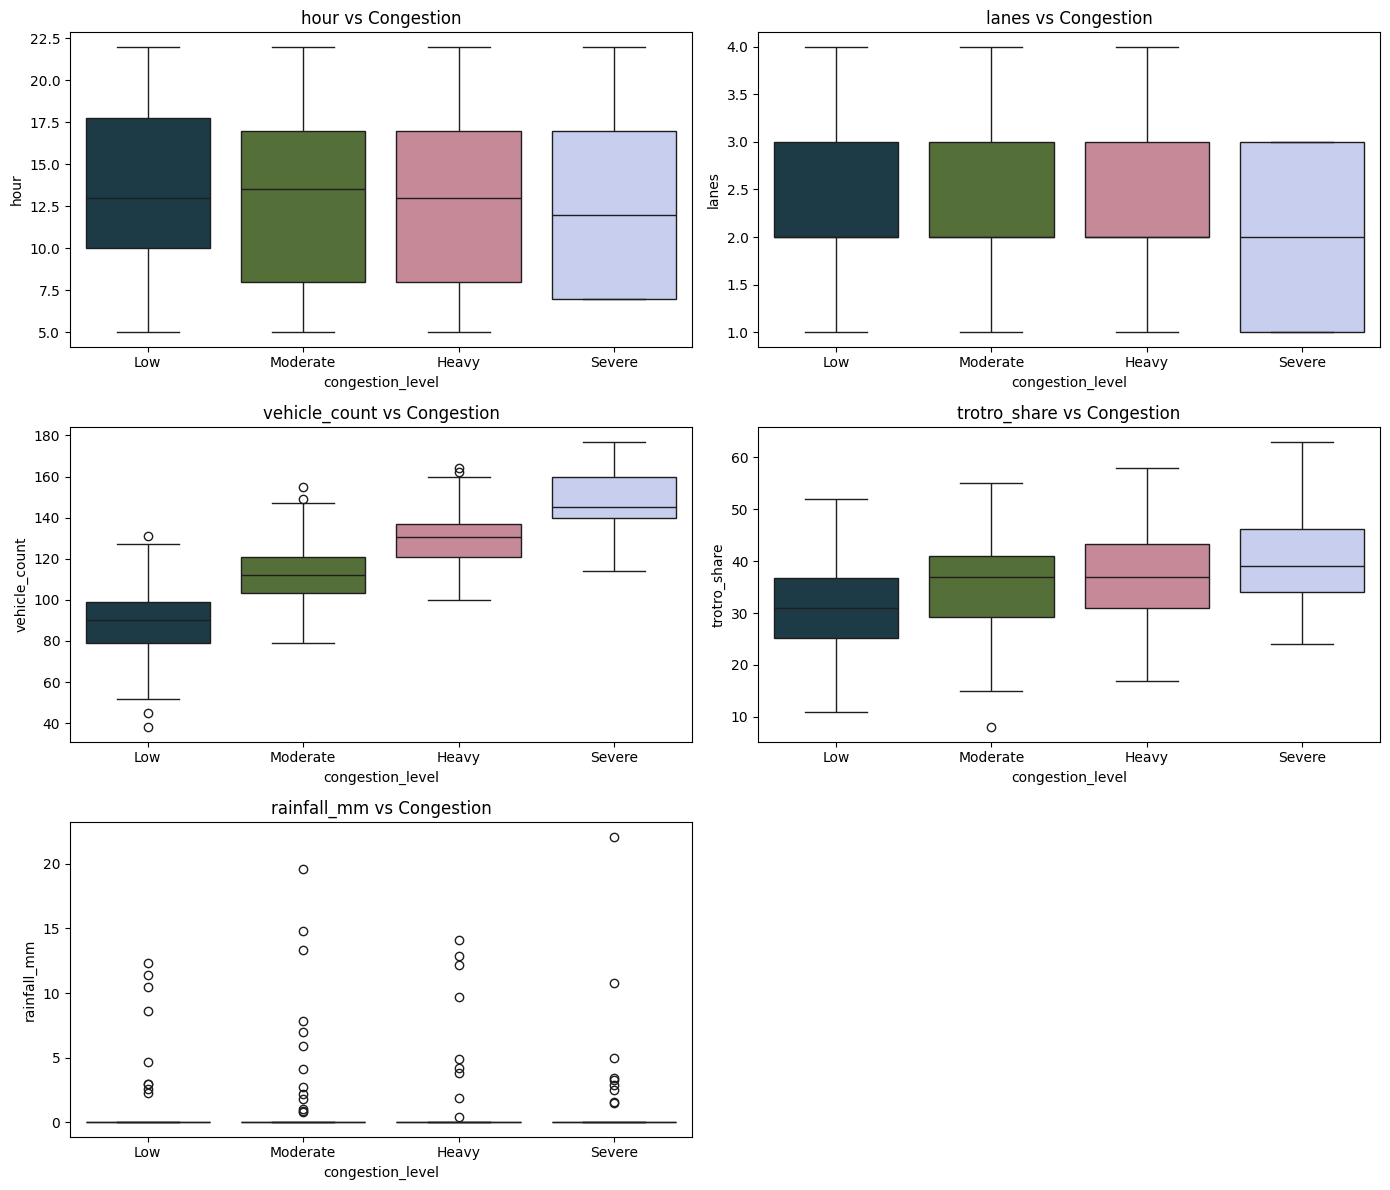

In [15]:
plt.figure(figsize=(14,12))
for i,col in enumerate(numerical_list,1):
    plt.subplot(3,2,i)
    sns.boxplot(x='congestion_level', y=col, data=df, order=order, palette='cubehelix')
    plt.title(col+' vs Congestion')
plt.tight_layout(); plt.show()

Inference: vehicle count, trotro share and rainfall rise with congestion; more lanes lower it.

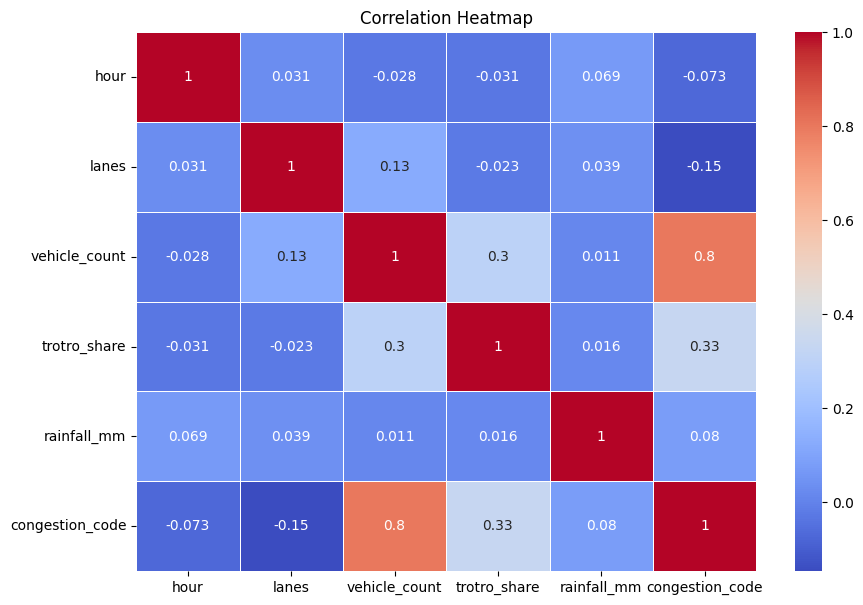

In [16]:
cong_map = {'Low':0,'Moderate':1,'Heavy':2,'Severe':3}
tmp = df[numerical_list].copy(); tmp['congestion_code'] = df.congestion_level.map(cong_map)
plt.figure(figsize=(10,7))
sns.heatmap(tmp.corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap'); plt.show()

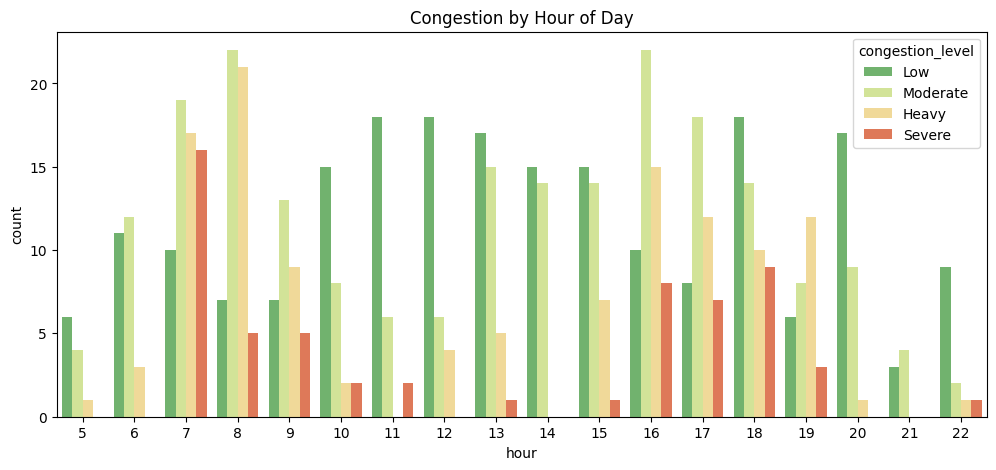

In [17]:
plt.figure(figsize=(12,5))
sns.countplot(x='hour', hue='congestion_level', data=df, hue_order=order, palette='RdYlGn_r')
plt.title('Congestion by Hour of Day'); plt.show()

Inference: morning (7-9) and evening (16-19) peaks drive most Heavy/Severe observations.

**Dummy variables**

In [18]:
df_model = df.copy()
# yes/no columns -> 1/0
for col in binary_cols:
    df_model[col] = (df_model[col]=='yes').astype(int)
# corridor and day_of_week -> dummy columns
df_model = pd.get_dummies(df_model, columns=['corridor','day_of_week'], drop_first=True).astype({c:int for c in []})
bool_cols = df_model.select_dtypes('bool').columns
df_model[bool_cols] = df_model[bool_cols].astype(int)
df_model.head()

,congestion_level,hour,lanes,vehicle_count,trotro_share,rainfall_mm,marketday,schoolzone,roadworks,trafficlight_working,...,corridor_Kentinkrono-Atonsu,corridor_Santasi Roundabout,corridor_Suame Magazine,corridor_Tafo-Pankrono,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
0,Low,13,2,90,29,0.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,Moderate,17,3,114,26,0.0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,Moderate,12,2,121,28,0.0,0,0,0,1,...,0,0,1,0,1,0,0,0,0,0
3,Low,12,4,98,26,0.0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
4,Moderate,17,3,121,43,0.0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0


In [19]:
df_model.shape

(600, 29)

**Train / test split (stratified so every congestion class appears in both sets)**

In [20]:
from sklearn.model_selection import train_test_split
np.random.seed(0)
y = df_model['congestion_level']
X = df_model.drop(columns='congestion_level')
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, test_size=0.25, random_state=100, stratify=y)
print(X_train.shape, X_test.shape)

(450, 28) (150, 28)


**Scale the numerical columns (fit on train only)**

In [21]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train[numerical_list] = scaler.fit_transform(X_train[numerical_list])
X_test[numerical_list] = scaler.transform(X_test[numerical_list])
X_train.head()

,hour,lanes,vehicle_count,trotro_share,rainfall_mm,marketday,schoolzone,roadworks,trafficlight_working,accident_reported,...,corridor_Kentinkrono-Atonsu,corridor_Santasi Roundabout,corridor_Suame Magazine,corridor_Tafo-Pankrono,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
440,0.000000,0.000000,0.330935,0.44,0.0,0,0,1,1,0,...,0,0,0,1,0,0,0,0,1,0
494,0.823529,0.666667,0.294964,0.40,0.0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
466,0.235294,0.666667,0.424460,0.38,0.0,0,0,1,1,0,...,0,0,0,0,0,0,1,0,0,0
304,0.588235,0.666667,0.431655,0.72,0.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
532,0.411765,0.333333,0.611511,0.60,0.0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0


**Baseline model: Logistic Regression**

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, y_train)
print('Logistic Regression accuracy:', round(accuracy_score(y_test, lr.predict(X_test)),3))

Logistic Regression accuracy: 0.713


**Main model: Random Forest Classifier**

In [23]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, max_depth=None, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
print('Random Forest accuracy:', round(accuracy_score(y_test, y_pred),3))

Random Forest accuracy: 0.74


**Cross-validation check**

In [24]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
scores = cross_val_score(rf, X_train, y_train, cv=cv)
print('CV accuracy per fold:', scores.round(3)); print('Mean CV accuracy:', scores.mean().round(3))

CV accuracy per fold: [0.667 0.722 0.589 0.622 0.756]
Mean CV accuracy: 0.671


**Evaluation of the model**

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred, labels=order))

              precision    recall  f1-score   support

         Low       0.88      0.79      0.83        53
    Moderate       0.64      0.75      0.69        52
       Heavy       0.65      0.67      0.66        30
      Severe       1.00      0.67      0.80        15

    accuracy                           0.74       150
   macro avg       0.79      0.72      0.74       150
weighted avg       0.76      0.74      0.74       150



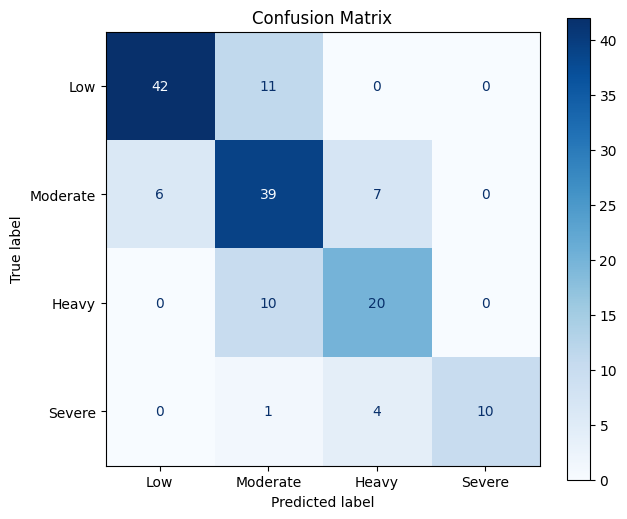

In [26]:
fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=order), display_labels=order).plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix'); plt.show()

**Which factors matter most?**

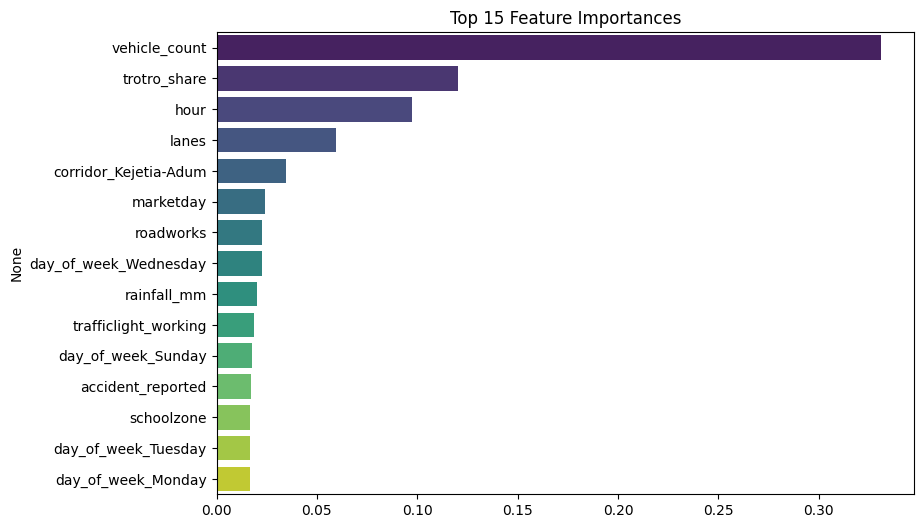

In [27]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9,6)); sns.barplot(x=imp.values, y=imp.index, palette='viridis')
plt.title('Top 15 Feature Importances'); plt.show()

Inference: peak hour traffic volume, market day, trotro share, accidents, roadworks and lane count are the main drivers; the model also learns that the central corridors are the hardest hit.

**Predict congestion for a new situation**

In [28]:
def predict_congestion(corridor, day_of_week, hour, lanes, vehicle_count, trotro_share, rainfall_mm,
                       marketday='no', schoolzone='no', roadworks='no', trafficlight_working='yes',
                       accident_reported='no', event_nearby='no'):
    row = pd.DataFrame([{'hour':hour,'lanes':lanes,'vehicle_count':vehicle_count,'trotro_share':trotro_share,
        'rainfall_mm':rainfall_mm,'marketday':marketday,'schoolzone':schoolzone,'roadworks':roadworks,
        'trafficlight_working':trafficlight_working,'accident_reported':accident_reported,'event_nearby':event_nearby,
        'corridor':corridor,'day_of_week':day_of_week}])
    for col in binary_cols: row[col] = (row[col]=='yes').astype(int)
    row = pd.get_dummies(row, columns=['corridor','day_of_week']).reindex(columns=X_train.columns, fill_value=0)
    row[numerical_list] = scaler.transform(row[numerical_list])
    return rf.predict(row)[0], dict(zip(rf.classes_, rf.predict_proba(row)[0].round(2)))

print(predict_congestion('Kejetia-Adum','Wednesday',8,2,150,45,0,marketday='yes'))
print(predict_congestion('Abuakwa-Sunyani Rd','Sunday',11,2,60,25,0))
print(predict_congestion('Santasi Roundabout','Friday',17,3,140,40,12,trafficlight_working='no'))

('Severe', {'Heavy': np.float64(0.1), 'Low': np.float64(0.0), 'Moderate': np.float64(0.01), 'Severe': np.float64(0.89)})
('Low', {'Heavy': np.float64(0.0), 'Low': np.float64(0.94), 'Moderate': np.float64(0.06), 'Severe': np.float64(0.0)})
('Moderate', {'Heavy': np.float64(0.35), 'Low': np.float64(0.08), 'Moderate': np.float64(0.41), 'Severe': np.float64(0.16)})
